# Deteksi Fault 4 Sensor Kelembaban Tanah: EDM-Fuzzy vs JSD-Fuzzy + ANN-LM

**Notebook sidang interaktif.** Semua angka dibaca dari hasil penelitian yang sudah
diekspor; tidak ada model yang dilatih ulang di sini, jadi tiap sel selesai dalam
hitungan detik.

Cara pakai: **Run All** sekali, lalu ubah pilihan di panel kontrol: panjang jendela
(N = 200/700/1000), hari mulai, sensor yang dirusak, kombinasi fault, intensitas,
dan seed. Fault dan entropi dihitung langsung dengan fungsi penelitian yang sama;
grafik dan tebakan model ikut berubah.

In [1]:
# === Setup 1/3: pustaka angka ===
import json, sys, time
from functools import lru_cache
from pathlib import Path
import numpy as np, pandas as pd

In [2]:
# === Setup 2/3: grafik dan widget ===
import matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, HTML, Markdown

In [3]:
# === Setup 3/3: lokasi file, mode presentasi ===

# Lokal: repo penelitian. Kaggle: file dataset `sidang-bahan` (datar) disusun ulang
# ke struktur folder repo di /kaggle/working/bahan memakai symlink.
BERKAS = {"cache_interaktif.npz": "sidang/assets", "model_sidang.npz": "sidang/assets",
          "deteksi_fault_core.py": ".",
          "11_rq5_f1_berpasangan.csv": "hasil11/exports", "11_sensor_ringkas.csv": "hasil11/exports",
          "statistik_sel.csv": "sidang/qa/hasil_uji", "statistik_lipatan.csv": "sidang/qa/hasil_uji",
          "efek_purge_permutasi.csv": "sidang/qa/hasil_uji"}
ROOT = next((p for p in [Path(".."), Path(".")]
             if (p / "sidang" / "assets" / "cache_interaktif.npz").exists()), None)
if ROOT is None:
    import glob
    ROOT = Path("/kaggle/working/bahan")
    for nama, folder in BERKAS.items():
        asal = glob.glob(f"/kaggle/input/**/{nama}", recursive=True)
        if asal:
            (ROOT / folder).mkdir(parents=True, exist_ok=True)
            tujuan = ROOT / folder / nama
            if not tujuan.exists():
                tujuan.symlink_to(asal[0])
C = np.load(ROOT / "sidang" / "assets" / "cache_interaktif.npz")
sys.path.insert(0, str(ROOT.resolve()))
import deteksi_fault_core as core   # rumus entropi dan simulator fault penelitian (notebook 11)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

_gaya = w.Output()
def _mode(presentasi):
    with _gaya:
        _gaya.clear_output()
        if presentasi:
            display(HTML("<style>.catatan-internal{display:none!important}</style>"))
tombol_mode = w.ToggleButton(value=False, description="Mode presentasi", icon="eye-slash",
                             tooltip="Sembunyikan semua catatan internal")
tombol_mode.observe(lambda ch: _mode(ch["new"]), "value")
display(w.HBox([tombol_mode, _gaya]))
print("Folder kerja:", ROOT.resolve())

Folder kerja: /Users/kelvin/apps/public-files


## 1. Masalahnya

Sensor kelembaban tanah di sistem irigasi bisa rusak diam-diam: nilainya bergeser,
melonjak, merayap naik, atau macet. Sistem yang percaya pada sensor rusak akan
menyiram terlalu banyak atau terlalu sedikit.

**Pertanyaan penelitian:** kalau sinyal 4 sensor dipotong per jendela waktu dan
tiap sensor diringkas dengan **entropi multiskala**, apakah mengganti ukuran
kemiripan **Euclidean (EDM-Fuzzy)** dengan **Jensen–Shannon Divergence
(JSD-Fuzzy)** membuat ANN-LM lebih baik mengenali (1) ada tidaknya fault,
(2) jenis/kombinasi fault, dan (3) sensor mana yang rusak?

## 2. Data: 4 sensor, ±98 hari

Sensor mencatat tiap 30 detik; broker menyinkronkan keempatnya lalu merata-rata
per 5 menit. Grafik di bawah: rata-rata per jam, seluruh periode.

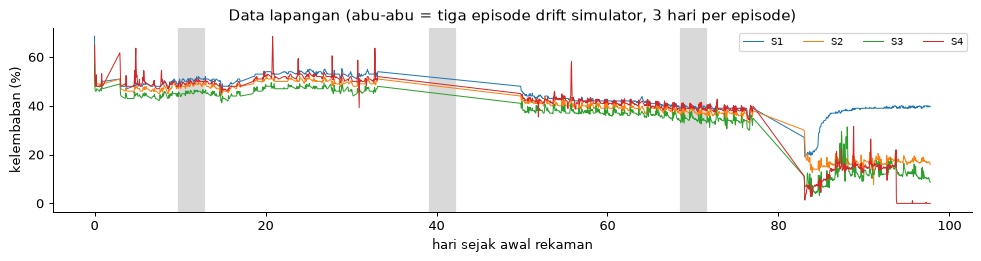

28,173 titik 5 menit = 97.8 hari


In [4]:
jam = C["ringkas_per_jam"]
hari = np.arange(len(jam)) / 24
fig, ax = plt.subplots(figsize=(11, 3))
for j in range(4):
    ax.plot(hari, jam[:, j], lw=0.8, label=f"S{j+1}")
for h0, h1 in core.drift_episode_days(int(C["n_sampel_5menit"])):
    ax.axvspan(h0, h1, color="0.85", zorder=0)
ax.set_xlabel("hari sejak awal rekaman"); ax.set_ylabel("kelembaban (%)")
ax.set_title("Data lapangan (abu-abu = tiga episode drift simulator, 3 hari per episode)")
ax.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()
print(f"{int(C['n_sampel_5menit']):,} titik 5 menit = {int(C['n_sampel_5menit']) * 300 / 86400:.1f} hari")

In [5]:
# === Panel kontrol (dipakai bagian 3, 4, dan 6) ===
# Model tersimpan dimuat di sini supaya pilihan panjang jendela = N yang modelnya ada.
MZ = np.load(ROOT / "sidang" / "assets" / "model_sidang.npz")
META = {int(k): v for k, v in json.loads(str(MZ["_meta"])).items()}
X5 = np.asarray(C["X5"], float); PER_HARI = int(86400 / core.SAMPLING_SECONDS)
METODE = [str(m) for m in C["metode"]]
FAULT4 = ["drift", "spike", "bias", "hardware"]

pil_N = w.Dropdown(options=[(f"N = {n} ({n * 300 / 3600:.0f} jam)", n) for n in META], value=700,
                   description="Panjang")
pil_hari = w.FloatSlider(value=10, min=0, max=round((len(X5) - max(META)) / PER_HARI, 1), step=0.5,
                         description="Mulai hari", continuous_update=False, readout_format=".1f")
pil_sensor = w.SelectMultiple(options=[(f"S{s+1}", s) for s in range(4)], value=(1,), rows=4,
                              description="Sensor rusak")
pil_fault = w.SelectMultiple(options=FAULT4, value=tuple(FAULT4), rows=4, description="Fault")
pil_int = w.FloatLogSlider(value=1, base=10, min=-1, max=2, step=0.1, description="Intensitas ×",
                           continuous_update=False, readout_format=".2g")
pil_seed = w.BoundedIntText(value=2026, min=0, max=10**6, description="Seed")
pil_lihat = w.Dropdown(options=[(f"S{s+1}", s) for s in range(4)], value=1, description="Gambar sensor")
PANEL = w.VBox([w.HBox([pil_N, pil_hari, pil_int]), w.HBox([pil_sensor, pil_fault, w.VBox([pil_seed, pil_lihat])])])
KONTROL = dict(n=pil_N, hari=pil_hari, sensor=pil_sensor, fault=pil_fault, k=pil_int, seed=pil_seed, lihat=pil_lihat)


def _skala(fn, kw, k):
    # Intensitas mengalikan amplitudo drift/spike/bias; peluang hardware dikali min(k, 5), maks 0,6.
    kw = dict(kw)
    if fn is core.simulate_bias_fault:
        kw["bias"] *= k
    elif fn is core.simulate_hardware_fault:
        kw = {a: min(0.6, v * min(k, 5)) for a, v in kw.items()}
    else:
        kw["intensity"] *= k
    return kw


@lru_cache(maxsize=32)
def deret_rusak(sensor, fault, k, seed):
    # Fault disuntikkan ke SELURUH deret lalu jendela dipotong, persis seperti data latih
    # (core.segment_and_label); urutan komponen = definisi kondisi di core.SCENARIOS.
    if not sensor or not fault:
        return X5, np.zeros(X5.shape, bool), "normal"
    kondisi = core.condition_for(fault)
    faults = [(fn, _skala(fn, kw, k)) for fn, kw in core.SCENARIOS[kondisi]]
    Y, M = core.inject_faults_multisensor(X5, faults, list(sensor), seed=seed)
    return Y, M, kondisi


@lru_cache(maxsize=2048)
def fitur_sensor(n, mulai, s, mi, kunci):
    # Entropi multiskala 1 sensor (15 skala). float32 seperti core.make_windows; seed 7 + 19·s
    # seperti core.concat_multisensor_features(seed=7) untuk jendela pertama.
    Y = X5 if kunci is None else deret_rusak(*kunci)[0]
    x = Y[mulai:mulai + n, s].astype(np.float32).astype(float)
    return core.entropy_1d(x, METODE[mi], sd=7 + 19 * s)


def jendela(n, hari, sensor, fault, k, seed, **_):
    sensor, fault = tuple(sorted(sensor)), tuple(f for f in FAULT4 if f in fault)
    mulai = min(int(round(hari * PER_HARI)), len(X5) - n)
    kunci = (sensor, fault, float(k), int(seed)) if sensor and fault else None
    Y, M, kondisi = deret_rusak(*kunci) if kunci else (X5, np.zeros(X5.shape, bool), "normal")
    F = {mi: (np.concatenate([fitur_sensor(n, mulai, s, mi, None) for s in range(4)]),
              np.concatenate([fitur_sensor(n, mulai, s, mi, kunci if s in sensor else None) for s in range(4)]))
         for mi in range(len(METODE))}
    return dict(mulai=mulai, bersih=X5[mulai:mulai + n], rusak=Y[mulai:mulai + n], mask=M[mulai:mulai + n],
                kondisi=kondisi, sensor=sensor, fault=fault, F=F)

def hidupkan(fn, kontrol=None, panel=None):
    # Tampilkan hasil fn(**pilihan) sebagai output sel biasa (terlihat juga di tampilan
    # statis) lalu perbarui di tempat setiap kali pilihan panel berubah.
    kontrol = kontrol or KONTROL
    display(panel or PANEL)
    pegangan = []
    def render(*_):
        isi = fn(**{k: v.value for k, v in kontrol.items()})
        if not pegangan:
            pegangan.extend(display(x, display_id=True) for x in isi)
        else:
            for h, x in zip(pegangan, isi):
                h.update(x)
        plt.close("all")
    for v in kontrol.values():
        v.observe(render, "value")
    render()

display(PANEL)

## 3. Fault disuntikkan ke data asli

Data lapangan dianggap **bersih**; fault dibuat dengan simulator lalu disuntikkan
ke satu sensor. Empat jenis: **drift** (merayap naik pelan), **spike** (lonjakan
sesaat), **bias** (bergeser tetap), **hardware** (macet/nilai hilang); "semua" =
keempatnya sekaligus.

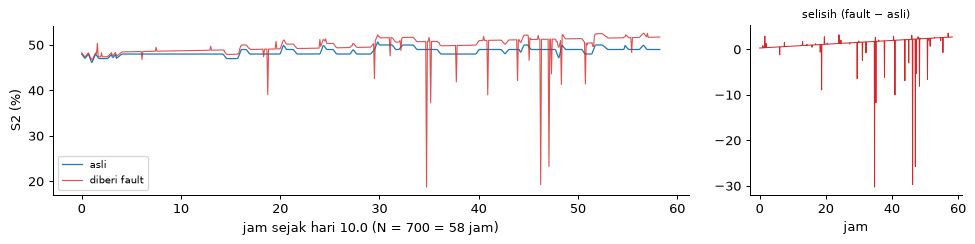

Kondisi simulator: **spike+bias+malfunc+drift** · porsi sampel yang kena fault di jendela ini: S1 **0%** · S2 **100%** · S3 **0%** · S4 **0%**

In [6]:
FIG_F, AX_F = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"width_ratios": [3, 1]})
L_asli, = AX_F[0].plot([], [], color="tab:blue", lw=1, label="asli")
L_rusak, = AX_F[0].plot([], [], color="tab:red", lw=0.9, alpha=0.8, label="diberi fault")
L_beda, = AX_F[1].plot([], [], color="tab:red", lw=0.8)
AX_F[0].legend(fontsize=8)
AX_F[1].set_title("selisih (fault − asli)", fontsize=9); AX_F[1].set_xlabel("jam")
FIG_F.tight_layout(); plt.close(FIG_F)

def gambar_fault(**p):
    # satu figur dipakai ulang; hanya data garis yang diganti (respons cepat)
    j, s, n = jendela(**p), p["lihat"], p["n"]
    t = np.arange(n) * 300 / 3600
    bersih, rusak = j["bersih"][:, s], j["rusak"][:, s]
    L_asli.set_data(t, bersih); L_rusak.set_data(t, rusak); L_beda.set_data(t, rusak - bersih)
    AX_F[0].set_ylabel(f"S{s+1} (%)")
    AX_F[0].set_xlabel(f"jam sejak hari {j['mulai'] / PER_HARI:.1f} (N = {n} = {n * 300 / 3600:.0f} jam)")
    for ax in AX_F:
        ax.relim(); ax.autoscale_view()
    porsi = " · ".join(f"S{q+1} **{j['mask'][:, q].mean():.0%}**" for q in range(4))
    return [FIG_F, Markdown(f"Kondisi simulator: **{j['kondisi']}** · porsi sampel yang kena fault di "
                            f"jendela ini: {porsi}")]

hidupkan(gambar_fault)

## 4. Entropi multiskala: EDM-Fuzzy vs JSD-Fuzzy

Tiap sensor diringkas menjadi **15 angka** (satu per skala τ = 1..15): seberapa
tidak teratur polanya ketika sinyal dilihat makin kasar. Empat sensor × 15 = **60
fitur** per jendela. Garis putus-putus = setelah fault.

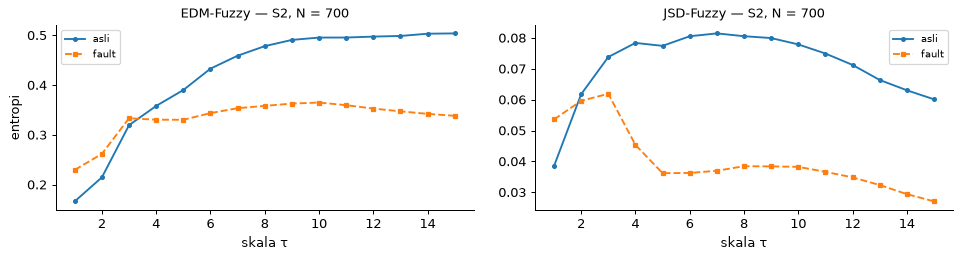

Rata-rata perubahan entropi S2 akibat fault: EDM-Fuzzy **0.103** · JSD-Fuzzy **0.033**

In [7]:
T_SK = core.T_SCALES; _tau = np.arange(1, T_SK + 1)
FIG_E, AX_E = plt.subplots(1, 2, figsize=(11, 2.8), sharex=True)
L_E = [(ax.plot(_tau, _tau * 0.0, "o-", ms=3, label="asli")[0],
        ax.plot(_tau, _tau * 0.0, "s--", ms=3, label="fault")[0]) for ax in AX_E]
for ax in AX_E:
    ax.set_xlabel("skala τ"); ax.legend(fontsize=8)
AX_E[0].set_ylabel("entropi"); FIG_E.tight_layout(); plt.close(FIG_E)

def gambar_entropi(**p):
    j, s = jendela(**p), p["lihat"]
    beda = []
    for mi, ax in enumerate(AX_E):
        asli, rusak = (f[s * T_SK:(s + 1) * T_SK] for f in j["F"][mi])
        L_E[mi][0].set_ydata(asli); L_E[mi][1].set_ydata(rusak)
        ax.set_title(f"{METODE[mi]} — S{s+1}, N = {p['n']}", fontsize=10)
        ax.relim(); ax.autoscale_view()
        beda.append(np.abs(rusak - asli).mean())
    return [FIG_E, Markdown(f"Rata-rata perubahan entropi S{s+1} akibat fault: " +
                            " · ".join(f"{METODE[mi]} **{beda[mi]:.3f}**" for mi in range(2)))]

hidupkan(gambar_entropi)

## 5. ANN dilatih dengan Levenberg–Marquardt (LM)

60 fitur → jaringan saraf kecil (1–2 lapisan tersembunyi) → kelas. Bobot dicari
dengan LM: langkah **(JᵀJ + λ·diag(JᵀJ))·Δ = −Jᵀr**. λ kecil ≈ Gauss–Newton
(cepat dekat minimum), λ besar ≈ turun gradien (hati-hati jauh dari minimum).
Coba geser λ pada contoh mini di bawah (satu neuron, dua bobot).

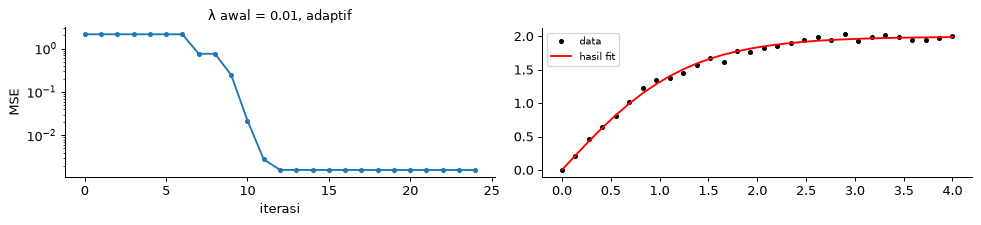

In [8]:
rng_toy = np.random.default_rng(0)
x_toy = np.linspace(0, 4, 30); y_toy = 2.0 * np.tanh(0.8 * x_toy) + rng_toy.normal(0, 0.05, 30)

def lm_mini(lam0, adaptif, iters=25):
    th = np.array([0.2, 3.0]); lam = lam0; hist = []
    for _ in range(iters):
        a, b = th; z = np.tanh(b * x_toy); r = a * z - y_toy
        J = np.column_stack([z, a * x_toy * (1 - z**2)])
        A = J.T @ J; g = J.T @ r
        step = np.linalg.solve(A + lam * np.diag(np.diag(A)) + 1e-12 * np.eye(2), -g)
        th_baru = th + step
        r_baru = th_baru[0] * np.tanh(th_baru[1] * x_toy) - y_toy
        if (r_baru**2).sum() < (r**2).sum():
            th = th_baru; lam = lam / 3 if adaptif else lam
        else:
            lam = lam * 2 if adaptif else lam
        hist.append(((th[0] * np.tanh(th[1] * x_toy) - y_toy) ** 2).mean())
    return th, hist

def gambar_lm(log_lambda, adaptif):
    th, hist = lm_mini(10.0 ** log_lambda, adaptif)
    fig, axs = plt.subplots(1, 2, figsize=(11, 2.6))
    axs[0].semilogy(hist, "o-", ms=3); axs[0].set_xlabel("iterasi"); axs[0].set_ylabel("MSE")
    axs[0].set_title(f"λ awal = {10.0 ** log_lambda:g}, {'adaptif' if adaptif else 'tetap'}", fontsize=10)
    axs[1].plot(x_toy, y_toy, "k.", label="data")
    axs[1].plot(x_toy, th[0] * np.tanh(th[1] * x_toy), "r-", label="hasil fit"); axs[1].legend(fontsize=8)
    plt.tight_layout()
    return [fig]

K_LM = dict(log_lambda=w.FloatSlider(value=-2, min=-4, max=3, step=0.5, description="log10 λ"),
            adaptif=w.Checkbox(value=True, description="λ adaptif (seperti penelitian)"))
hidupkan(gambar_lm, K_LM, w.HBox(list(K_LM.values())))

## 6. Tebakan model tersimpan untuk jendela pilihan

Model tersimpan (`models/`, satu set per panjang jendela N = 200/700/1000) dipakai
langsung: **S1** menjawab "normal atau rusak", model skenario sesuai jumlah jenis
fault menjawab jenis/kombinasinya, dan model sensor-ID menunjuk sensor yang rusak
(skor > 0,5).

In [9]:
# Bobot model N = 200/700/1000 dari models/ (diekspor ke numpy oleh sidang/qa/buat_cache_interaktif.py,
# prediksinya sudah dicek sama dengan model asli; selisih < 1e-9). MZ dan META dimuat di panel kontrol.

def maju(kunci, X, sensor=False):
    X = np.array(X, float, copy=True)
    nan = np.isnan(X)
    if nan.any():
        X[nan] = np.broadcast_to(MZ[kunci + "|fill"], X.shape)[nan]
    a = (X - MZ[kunci + "|mean"]) / MZ[kunci + "|scale"]
    n, act = int(MZ[kunci + "|n"]), str(MZ[kunci + "|act"])
    for i in range(n):
        a = a @ MZ[f"{kunci}|W{i}"] + MZ[f"{kunci}|b{i}"]
        if i < n - 1:
            a = np.maximum(a, 0.0) if act == "relu" else np.tanh(a)
    if sensor:
        return a
    e = np.exp(a - a.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

MODELS = {}
for k in sorted({"|".join(x.split("|")[:3]) for x in MZ.files if not x.startswith("_")}):
    nn, sc, met = k.split("|")
    MODELS[(int(nn[1:]), sc, met)] = {"class_names": [str(c) for c in MZ[k + "|kelas"]],
                                      "detektor": lambda X, k=k: maju(k + "|det", X),
                                      "sensor_id": (lambda X, k=k: maju(k + "|sen", X, sensor=True))
                                                   if k + "|sen|n" in MZ.files else None,
                                      "cv_f1_nb11": float(MZ[k + "|cv_f1_nb11"])}
SKEN_KELAS = {core.SCEN_SHORT[sc]: cls for sc, cls in core.LADDER.items()}
def kelas_benar(sc, kondisi):
    return next(nama for nama, kond in SKEN_KELAS[sc] if kondisi in kond or (sc == "S1" and kondisi != "normal"
                                                                                and nama == "faulty"))
for n, m in META.items():
    print(f"N = {n}: {sum(k[0] == n for k in MODELS)} model | dibuat {m['dibuat']} | commit {m['commit']}")

N = 200: 10 model | dibuat 2026-11-21T09:18:21+00:00 | commit 77832c6
N = 700: 10 model | dibuat 2026-11-20T02:04:57+00:00 | commit da6f6d3
N = 1000: 10 model | dibuat 2026-11-21T09:54:16+00:00 | commit 77832c6


In [10]:
def tebak(**p):
    j, n = jendela(**p), p["n"]
    sken = ["S1", "S2", "S3", "S4", "S5"][len(j["fault"])] if j["sensor"] else "S1"
    baris, sens = [], []
    for mi, met in enumerate(METODE):
        X2 = np.vstack(j["F"][mi])
        for sc in dict.fromkeys(["S1", sken]):
            b = MODELS[(n, sc, met)]; P = b["detektor"](X2)
            for wi, nama in enumerate(["asli", "diberi fault"]):
                kk = int(P[wi].argmax())
                baris.append({"Jendela": nama, "Model": sc, "Metode": met, "Tebakan": b["class_names"][kk],
                              "Yakin": f"{P[wi, kk]:.0%}",
                              "Benar": kelas_benar(sc, "normal" if wi == 0 else j["kondisi"]),
                              "F1 CV (NB11)": round(b["cv_f1_nb11"], 3)})
        if j["sensor"] and MODELS[(n, sken, met)]["sensor_id"] is not None:
            skor = MODELS[(n, sken, met)]["sensor_id"](j["F"][mi][1][None])[0]
            sens.append({"Metode": met, **{f"S{q+1}": round(float(v), 2) for q, v in enumerate(skor)},
                         "Ditebak rusak": ", ".join(f"S{q+1}" for q, v in enumerate(skor) if v > 0.5) or "-",
                         "Benar": ", ".join(f"S{q+1}" for q in j["sensor"])})
    isi = [Markdown(f"**N = {n}, hari {j['mulai'] / PER_HARI:.1f}, kondisi `{j['kondisi']}`, intensitas "
                    f"×{p['k']:.2g}.** Model {sken} dipilih sesuai jumlah jenis fault (1 → S2, 2 → S3, "
                    f"3 → S4, 4 → S5). Intensitas latih = ×1."),
           pd.DataFrame(baris)]
    if sens:
        isi += [Markdown("**Sensor mana yang rusak** (skor > 0,5 = rusak):"), pd.DataFrame(sens)]
    else:
        isi += [Markdown("Tidak ada sensor yang dirusak: hanya model S1 (normal vs rusak) yang relevan."),
                pd.DataFrame()]
    return isi

hidupkan(tebak)

**N = 700, hari 10.0, kondisi `spike+bias+malfunc+drift`, intensitas ×1.** Model S5 dipilih sesuai jumlah jenis fault (1 → S2, 2 → S3, 3 → S4, 4 → S5). Intensitas latih = ×1.

,Jendela,Model,Metode,Tebakan,Yakin,Benar,F1 CV (NB11)
0,asli,S1,EDM-Fuzzy,fault free,56%,fault free,0.595
1,diberi fault,S1,EDM-Fuzzy,faulty,72%,faulty,0.595
2,asli,S5,EDM-Fuzzy,fault free,84%,fault free,0.804
3,diberi fault,S5,EDM-Fuzzy,fault free,76%,drift+spike+bias+HW,0.804
4,asli,S1,JSD-Fuzzy,faulty,74%,fault free,0.671
5,diberi fault,S1,JSD-Fuzzy,faulty,79%,faulty,0.671
6,asli,S5,JSD-Fuzzy,fault free,60%,fault free,0.872
7,diberi fault,S5,JSD-Fuzzy,drift+spike+bias+HW,51%,drift+spike+bias+HW,0.872


**Sensor mana yang rusak** (skor > 0,5 = rusak):

,Metode,S1,S2,S3,S4,Ditebak rusak,Benar
0,EDM-Fuzzy,0.22,0.39,0.27,1.31,S4,S2
1,JSD-Fuzzy,0.15,1.13,0.71,0.92,"S2, S3, S4",S2


## 7. Hasil utama (notebook 11, LM asli, 15 sel = 5 skenario × 3 panjang jendela)

Nilai = F1 makro rata-rata 5 lipatan CV. Hijau = JSD lebih tinggi.

In [11]:
f1 = pd.read_csv(ROOT / "hasil11" / "exports" / "11_rq5_f1_berpasangan.csv")
f1 = f1[pd.to_numeric(f1["N_window"], errors="coerce").notna()].copy()
f1["N"] = f1["N_window"].astype(float).astype(int)
tabel = f1.pivot(index="Scenario", columns="N", values="Difference")
display(Markdown("**Selisih F1 (JSD − EDM)** per sel:"))
display(tabel.style.format("{:+.3f}").background_gradient(cmap="RdYlGn", vmin=-0.1, vmax=0.1))
r = f1[["EDM-Fuzzy F1", "JSD-Fuzzy F1"]].astype(float)
print(f"JSD menang {int((f1['Difference'].astype(float) > 0).sum())} dari {len(f1)} sel | "
      f"rata-rata F1 EDM {r['EDM-Fuzzy F1'].mean():.3f} vs JSD {r['JSD-Fuzzy F1'].mean():.3f}")
sid = pd.read_csv(ROOT / "hasil11" / "exports" / "11_sensor_ringkas.csv")
display(Markdown("**Identifikasi sensor** (dirantai dari prediksi out-of-fold):")); display(sid)

**Selisih F1 (JSD − EDM)** per sel:

N,200,700,1000
Scenario,,,
S1,-0.019,+0.077,+0.178
S2,+0.015,+0.019,-0.016
S3,-0.031,+0.013,-0.056
S4,+0.030,+0.087,+0.018
S5,+0.016,+0.068,+0.023


JSD menang 11 dari 15 sel | rata-rata F1 EDM 0.458 vs JSD 0.486


**Identifikasi sensor** (dirantai dari prediksi out-of-fold):

,N_window,Scenario,Method,F1,ROC_AUC
0,200,S1,EDM-Fuzzy,0.420,0.530
1,200,S1,JSD-Fuzzy,0.644,0.820
2,200,S2,EDM-Fuzzy,0.575,0.599
3,200,S2,JSD-Fuzzy,0.543,0.609
4,200,S3,EDM-Fuzzy,0.582,0.584
5,200,S3,JSD-Fuzzy,0.621,0.659
6,200,S4,EDM-Fuzzy,0.742,0.757
7,200,S4,JSD-Fuzzy,0.684,0.694
8,200,S5,EDM-Fuzzy,0.815,0.854
9,200,S5,JSD-Fuzzy,0.788,0.880


## 8. Seberapa kuat buktinya?

Uji berpasangan per notebook, ditambah ukuran efek (Cohen dz), interval
kepercayaan bootstrap 95 % untuk selisih rata-rata, dan koreksi Holm untuk tiga
panjang jendela.

In [12]:
st = pd.read_csv(ROOT / "sidang" / "qa" / "hasil_uji" / "statistik_sel.csv")
kol = ["notebook", "N", "menang_JSD", "n_sel", "rerata_selisih", "p_t", "p_wilcoxon",
       "p_t_holm_3N", "cohen_dz", "ci95_bawah", "ci95_atas"]
display(st[kol].style.format({c: "{:.3f}" for c in kol[4:]}, na_rep="—"))
p_lip = ROOT / "sidang" / "qa" / "hasil_uji" / "statistik_lipatan.csv"
if p_lip.exists():
    display(Markdown("**Tingkat lipatan, N = 700** (arsitektur tetap; t terkoreksi Nadeau–Bengio):"))
    display(pd.read_csv(p_lip).round(3))

,notebook,N,menang_JSD,n_sel,rerata_selisih,p_t,p_wilcoxon,p_t_holm_3N,cohen_dz,ci95_bawah,ci95_atas
0,NB10,200,3,5,0.007,0.643,0.625,0.967,0.224,-0.017,0.030
1,NB10,700,5,5,0.055,0.016,0.062,0.048,1.790,0.030,0.079
2,NB10,1000,3,5,0.030,0.483,0.625,0.967,0.345,-0.028,0.110
3,NB10,gabungan,11,15,0.031,0.052,0.041,—,0.549,0.005,0.061
4,NB11,200,3,5,0.002,0.854,1.000,0.997,0.088,-0.019,0.021
5,NB11,700,5,5,0.053,0.027,0.062,0.081,1.524,0.026,0.079
6,NB11,1000,3,5,0.029,0.499,0.625,0.997,0.332,-0.032,0.108
7,NB11,gabungan,11,15,0.028,0.076,0.107,—,0.495,0.002,0.058
8,NB14,200,5,5,0.100,0.010,0.062,0.030,2.057,0.064,0.136
9,NB14,700,3,5,0.056,0.199,0.312,0.199,0.687,-0.008,0.120


**Tingkat lipatan, N = 700** (arsitektur tetap; t terkoreksi Nadeau–Bengio):

,skenario,varian,k,F1_EDM,F1_JSD,rerata_selisih,p_t_biasa,t_NB,p_NB,cohen_dz,n_latih,n_uji,p_NB_holm_5skenario
0,S1,purge,5,0.570,0.674,0.104,0.001,4.927,0.008,3.539,100.0,31.6,0.039
1,S1,standar,5,0.642,0.677,0.035,0.415,0.605,0.578,0.406,126.4,31.6,1.000
2,S2,purge,5,0.259,0.274,0.014,0.835,0.137,0.897,0.099,245.6,79.0,1.000
3,S2,standar,5,0.303,0.324,0.022,0.547,0.438,0.684,0.294,316.0,79.0,1.000
4,S3,purge,5,0.224,0.234,0.010,0.357,0.643,0.555,0.465,342.0,110.6,1.000
5,S3,standar,5,0.236,0.228,-0.007,0.611,-0.367,0.732,-0.246,442.4,110.6,1.000
6,S4,purge,5,0.345,0.355,0.010,0.596,0.360,0.737,0.257,255.4,79.0,1.000
7,S4,standar,5,0.353,0.396,0.043,0.163,1.138,0.319,0.763,316.0,79.0,1.000
8,S5,purge,5,0.797,0.833,0.036,0.211,0.926,0.407,0.665,100.2,31.6,1.000
9,S5,standar,5,0.795,0.821,0.025,0.267,0.859,0.439,0.576,126.4,31.6,1.000


## 9. Kelemahan yang kami ketahui (dan apa yang sudah diukur)

In [13]:
p_ef = ROOT / "sidang" / "qa" / "hasil_uji" / "efek_purge_permutasi.csv"
if p_ef.exists():
    ef = pd.read_csv(p_ef)
    display(Markdown("**Purge** = buang jendela latih yang bertumpang-tindih waktu dengan jendela uji. "
                     "**Permutasi** = label latih diacak; F1 harus turun ke tingkat tebakan."))
    display(ef.round(3))
else:
    print("Hasil uji purge/permutasi belum tersedia.")

**Purge** = buang jendela latih yang bertumpang-tindih waktu dengan jendela uji. **Permutasi** = label latih diacak; F1 harus turun ke tingkat tebakan.

,skenario,metode,F1_standar,F1_purge,purge_minus_standar,lipatan,F1_permutasi,tebakan_F1_makro
0,S1,EDM-Fuzzy,0.642,0.570,-0.072,5,0.446,0.500
1,S1,JSD-Fuzzy,0.677,0.674,-0.003,5,0.508,0.500
2,S2,EDM-Fuzzy,0.303,0.259,-0.043,5,NaN,0.200
3,S2,JSD-Fuzzy,0.324,0.274,-0.051,5,NaN,0.200
4,S3,EDM-Fuzzy,0.236,0.224,-0.012,5,NaN,0.143
5,S3,JSD-Fuzzy,0.228,0.234,0.006,5,NaN,0.143
6,S4,EDM-Fuzzy,0.353,0.345,-0.008,5,NaN,0.200
7,S4,JSD-Fuzzy,0.396,0.355,-0.041,5,NaN,0.200
8,S5,EDM-Fuzzy,0.795,0.797,0.001,5,0.496,0.500
9,S5,JSD-Fuzzy,0.821,0.833,0.012,5,0.489,0.500


| Jenis | Kelemahan | Dampak |
|---|---|---|
| Internal | Jendela bersebelahan berbagi setengah sampel di batas grup CV | skor absolut sedikit optimistis; berlaku sama untuk EDM dan JSD |
| Konstruk | Fault disimulasikan, bukan kerusakan nyata | hasil berlaku untuk bentuk fault yang dimodelkan |
| Konstruk | *Centering* menghapus bias tetap | bias tidak terdeteksi oleh kedua metode |
| Statistik | 15 sel tidak saling bebas; banyak uji | p gabungan dibaca hati-hati, dilengkapi Holm/dz/CI |
| Eksternal | Satu lokasi, 4 sensor, ±98 hari | perlu validasi di lokasi/sensor lain |

## 10. Kesimpulan

1. Entropi multiskala 4 sensor + ANN-LM dapat mendeteksi fault dan menunjuk sensor
   yang rusak, paling baik untuk hardware/macet dan kombinasi banyak fault.
2. Mengganti Euclidean dengan **Jensen–Shannon Divergence** memberi keunggulan yang
   konsisten; kekuatan statistiknya bergantung pada bentuk fault (lihat bagian 8).
3. Bias tetap dan drift kecil tetap sulit: keterbatasan ini berasal dari
   *centering* di dalam entropi, bukan dari classifier.